In [18]:
from pyspark.sql import SparkSession
import geopandas as gpd
import matplotlib.pyplot as plt
from pyspark.sql.functions import col, regexp_replace
from matplotlib.colors import Normalize

In [ ]:
spark = (
    SparkSession.builder
    .appName("MySparkApp")
    .master("local[*]")  # use all available cores locally; change if running on a cluster
    .config("spark.sql.shuffle.partitions", 16)
    .config("spark.default.parallelism", 16)
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")  # optional: reduce log noise

print(f"Shuffle partitions: {spark.conf.get('spark.sql.shuffle.partitions')}")

Shuffle partitions: 16


### Visualise Raw Data and Schema

In [6]:
raw_df = spark.read.csv("../rea_data/domain/Data/vic_rentals_all.csv", header=True, inferSchema=True)   
raw_df.show(5)

26/09/12 01:35:24 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


+----------+----------------+--------+-----------+------+--------------------+-----------+-----------+--------+---------+---------+--------------------+-------------------+----------+---------+-------------------+--------------+-----------+-----------+-----------+----------------+------------+---------------+--------------------+--------------------+---------+--------------------+--------------------+--------------------+---------+
|listing_id|          suburb|postcode|weekly_rent|  bond|      available_date|date_listed|days_listed|bedrooms|bathrooms|carspaces|       property_type|            address|       lat|      lon|       scraped_date|domain_page_id|property_id|photo_count|video_count|floorplans_count|virtual_tour|   primary_type|      secondary_type|              agency|agency_id|         agent_names| structured_features|                 url|land_area|
+----------+----------------+--------+-----------+------+--------------------+-----------+-----------+--------+---------+-------

In [7]:
raw_df.printSchema()

root
 |-- listing_id: string (nullable = true)
 |-- suburb: string (nullable = true)
 |-- postcode: string (nullable = true)
 |-- weekly_rent: string (nullable = true)
 |-- bond: double (nullable = true)
 |-- available_date: string (nullable = true)
 |-- date_listed: date (nullable = true)
 |-- days_listed: double (nullable = true)
 |-- bedrooms: double (nullable = true)
 |-- bathrooms: double (nullable = true)
 |-- carspaces: double (nullable = true)
 |-- property_type: string (nullable = true)
 |-- address: string (nullable = true)
 |-- lat: double (nullable = true)
 |-- lon: double (nullable = true)
 |-- scraped_date: timestamp (nullable = true)
 |-- domain_page_id: string (nullable = true)
 |-- property_id: string (nullable = true)
 |-- photo_count: double (nullable = true)
 |-- video_count: double (nullable = true)
 |-- floorplans_count: double (nullable = true)
 |-- virtual_tour: boolean (nullable = true)
 |-- primary_type: string (nullable = true)
 |-- secondary_type: string (nu

In [15]:
raw_df = raw_df.withColumn(
    "weekly_rent",
    regexp_replace(col("weekly_rent"), "[^0-9.]", "").cast("double")
)

### Map of Raw Addresses

/home/jovinguyen/miniconda3/envs/tf_env/lib/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/jovinguyen/miniconda3/envs/tf_env/lib/python3.12/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


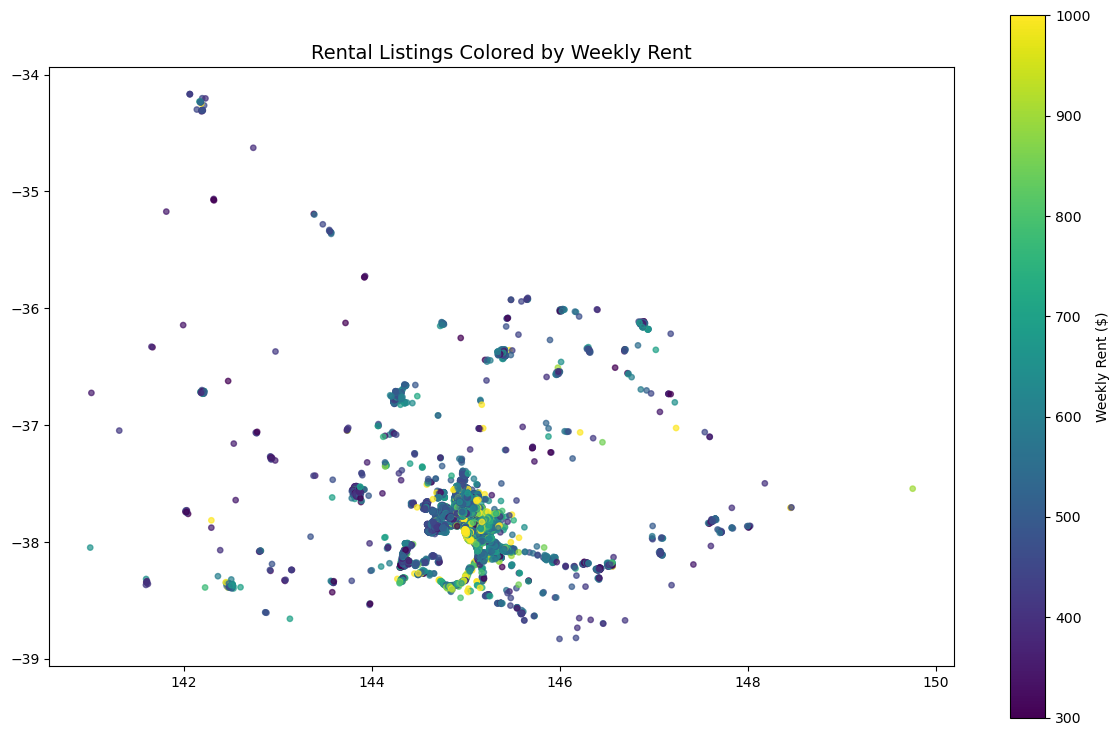

In [19]:
pdf = raw_df.dropna(
    subset=["lat", "lon", "weekly_rent"]
).toPandas()

gdf = gpd.GeoDataFrame(
    pdf,
    geometry=gpd.points_from_xy(pdf["lon"], pdf["lat"]),
    crs="EPSG:4326"
)

fig, ax = plt.subplots(figsize=(12, 12))

gdf.plot(
    ax=ax,
    column="weekly_rent",
    cmap="viridis",
    markersize=15,
    alpha=0.7,
    legend=True,
    norm=Normalize(vmin=300, vmax=1000),
    legend_kwds={
        "label": "Weekly Rent ($)",
        "shrink": 0.6
    }
)

ax.set_title("Rental Listings Colored by Weekly Rent", fontsize=14)
plt.tight_layout()
plt.show()
